In [36]:
import numpy as np

x = np.array([1, 6.7])
theta = np.array([0.049, -0.34])
lr = 0.01
y = 9.1
print(x)
print(theta)

[1.  6.7]
[ 0.049 -0.34 ]


In [37]:
def predict(x, theta):
    return theta.T.dot(x)
y_pred = predict(x, theta)
print(y_pred)

-2.229


In [38]:
def compute_loss(y_hat, y):
    return (y_hat - y) ** 2

loss = compute_loss(y_pred, y)
print(loss)

128.34624100000002


In [39]:
def compute_gradient(x, y_hat, y):
    return 2 * x * (y_hat - y)

gradient = compute_gradient(x, y_pred, y)
print(gradient)

[ -22.658  -151.8086]


In [40]:
def update_weights(theta, lr, gradient):
    theta = theta - lr * gradient
    return theta


theta = update_weights(theta, lr, gradient)
print(theta)

[0.27558  1.178086]


In [41]:
# After training

y_pred = predict(x, theta)
print(y_pred)

8.1687562


In [42]:
loss = compute_loss(y_pred, y)
print(loss)

0.867215015038438


In [77]:
import matplotlib.pyplot as plt

data = np.genfromtxt('data/data.csv', delimiter=',')

N = 4
areas = data[:, 0].reshape(1, N)
print(areas)
ys = data[:, 1].reshape(N, )
print(ys)

print(areas.shape)
print(ys.shape)

[[6.7 4.6 3.5 5.5]]
[9.1 5.9 4.6 6.7]
(1, 4)
(4,)


In [74]:
X = np.vstack([np.ones((1, N)), areas])
print(X)

[[1.  1.  1.  1. ]
 [6.7 4.6 3.5 5.5]]


In [84]:
epoch_max = 10
theta = np.array([0.049, -0.34])
losses = []
for epoch in range(epoch_max):
    for i in range(N):
        x = X[:, i]
        y = ys[i]

        y_hat = predict(x, theta)

        loss = compute_loss(y_hat, y)
        losses.append(loss)
        gradient = compute_gradient(x, y_hat, y)

        theta = update_weights(theta, lr, gradient)

print(theta)


[0.2335058  1.21100306]


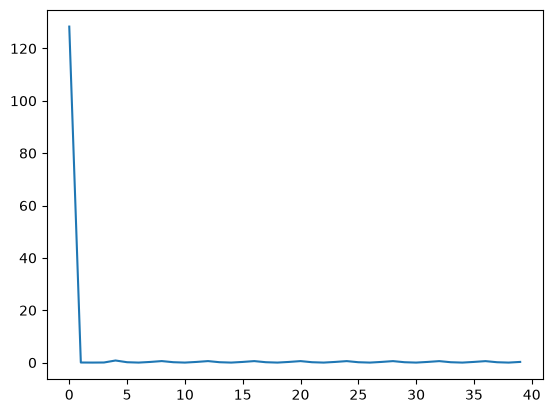

In [90]:
plt.plot(losses)

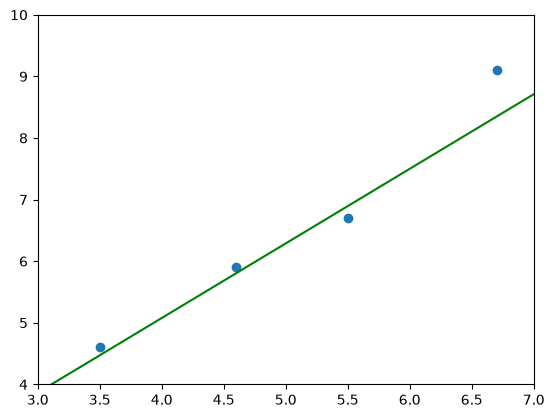

In [100]:
x_data = range(2, 8)
predicted_b, predicted_w = theta
y_data = [x * predicted_w + predicted_b for x in x_data]
plt.plot(x_data, y_data, 'g')
plt.scatter(areas, ys)
plt.xlim(3, 7)
plt.ylim(4, 10)
plt.show()